In [1]:
# Libraries
import re # not called in the code, just a remnant
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from scipy.stats import ks_1samp, shapiro, norm, probplot
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import xml.etree.ElementTree as ET # again not called in the code but was necessary for formating the original raw data that was in html
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from nltk.sentiment import SentimentIntensityAnalyzer


In [2]:
# Load Dataset
file_path = 'AllReviews.xlsx'
df = pd.read_excel(file_path)

# Setting the target value
target = 'Sentiment'
print("Label distribution:", Counter(df[target]))

# Splitting features and values
X = df.drop(columns=[target])
y = df[target]

# Removal of the meaningless values before checking for normal distribution
X_clean = X.drop(columns=['unique_id', 'asin', 'product_name', 'product_type', 'title', 'date', 'reviewer', 'reviewer_location', 'review_text', 'helpful'])

Label distribution: Counter({1: 1000, 0: 1000})


rating - Shapiro-Wilk p-value: 1.4096310708382553e-46 = Non Normal Distribution
rating - Kolmogorov-Smirnov p-value: 3.095427736904348e-85 = Non Normal Distribution


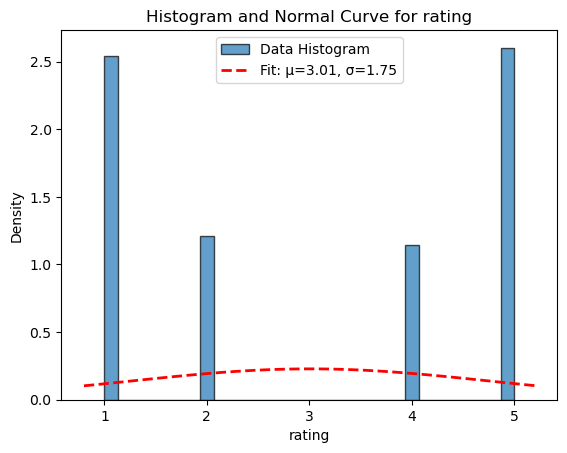

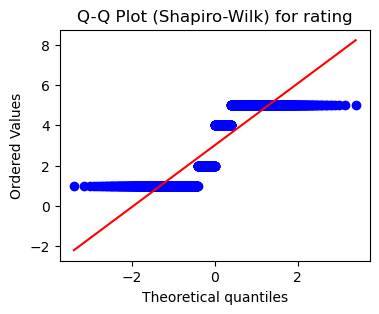

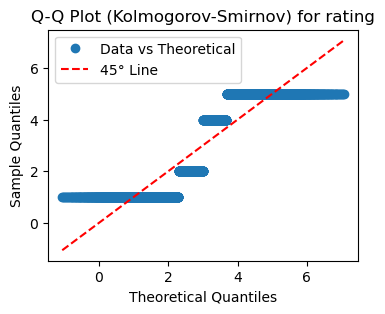

In [3]:
# Normal Distribution Test (Shapiro-Wilk Test, Kolmogorov-Smirnov Test and Histogram)
# Repeat for every column
for column in X_clean.columns:
    # Fitting into normal distribution
    data = X_clean[column].dropna() # Clearing NaN values if they exist
    mu, sigma = norm.fit(data)
    # Shapiro-Wilk Test for normal distribution check
    # It is known that Shapiro-Wilk is better for smaller sample sizes as it is more sensitive for tails/tips 
    stat, p1 = shapiro(data)
    #print(f"{column} - Shapiro-Wilk p-value: {p1}")
    if p1 < 0.05:
        print(f"{column} - Shapiro-Wilk p-value: {p1} = Non Normal Distribution")
    else:
        print(f"{column} - Shapiro-Wilk p-value: {p1} = Normal Distribution")
    # Kolmogorov-Smirnov Test for normal distribution check
    stat, p2 = ks_1samp(data, lambda x: norm.cdf(x, loc=mu, scale=sigma))
    #print(f"{column} - Kolmogorov-Smirnov p-value: {p2}")
    if p2 < 0.05:
        print(f"{column} - Kolmogorov-Smirnov p-value: {p2} = Non Normal Distribution")
    else:
        print(f"{column} - Kolmogorov-Smirnov p-value: {p2} = Normal Distribution")
    
    # Creating Histogram
    plt.hist(data, bins=30, density=True, edgecolor='black', alpha=0.7, label="Data Histogram")
    
    # Fitting Curves
    xmin, xmax = plt.xlim()  # take x axis limits
    x = np.linspace(xmin, xmax, 100)  # create x values
    p = norm.pdf(x, mu, sigma)  # Calculating Probability Density Function
    plt.plot(x, p, 'r--', linewidth=2, label=f"Fit: μ={mu:.2f}, σ={sigma:.2f}")
    
    # Adding Head and Labes
    plt.title(f"Histogram and Normal Curve for {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    # Q-Q plot (Shapiro-Wilk)
    plt.figure(figsize=(4, 3))
    probplot(data, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot (Shapiro-Wilk) for {column}")
    plt.show()

    # Q-Q plot (Kolmogorov-Smirnov)
    # Here we use theoric normal distribution parameters (mu, sigma)
    theoretical_quantiles = np.sort(norm.ppf(np.linspace(0.01, 0.99, len(data)), loc=mu, scale=sigma))
    actual_quantiles = np.sort(data)
    plt.figure(figsize=(4, 3))
    plt.plot(theoretical_quantiles, actual_quantiles, 'o', label="Data vs Theoretical")
    plt.plot([theoretical_quantiles.min(), theoretical_quantiles.max()], 
             [theoretical_quantiles.min(), theoretical_quantiles.max()], 'r--', label="45° Line")
    plt.title(f"Q-Q Plot (Kolmogorov-Smirnov) for {column}")
    plt.xlabel("Theoretical Quantiles")
    plt.ylabel("Sample Quantiles")
    plt.legend()
    plt.show()

In [4]:
#nltk.download('punkt_tab')
#nltk.download('stopwords')

# Use 'review_text' as the text column and 'Sentiment' as label column (1: pos, 0: neg)
texts = df['review_text'].astype(str)
labels = df['Sentiment']

# Text preprocessing function
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()
    # Tokenize
    tokens = word_tokenize(text)
    # Remove punctuation and stopwords
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word.isalpha() and word not in stop_words]
    # Stemming
    stemmer = SnowballStemmer("english")
    tokens = [stemmer.stem(word) for word in tokens]
    return " ".join(tokens)

# Apply preprocessing
df['cleaned_review'] = df['review_text'].apply(preprocess_text)

# Display the first few processed rows
df[['review_text', 'cleaned_review', 'Sentiment']].head()

,review_text,cleaned_review,Sentiment
0,I received my Kingston 256MB SD card just as a...,receiv kingston sd card advertis unit came mai...,1
1,"Works well, especially for anyone who still ha...",work well especi anyon still old consol system...,1
2,Not as easy to use as a larger Panasonic I use...,easi use larger panason use otherwis fine good...,1
3,It worked much better than expected. The page ...,work much better expect page clip also good on...,1
4,It's speedy and space saving and inexpensive. ...,speedi space save inexpens bought replac belki...,1


In [5]:
# nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

# Run the polarity score on the entire dataset
res = {}
for i, row in df.iterrows():
    text = row['review_text']
    myid = row['unique_id']
    res[myid] = sia.polarity_scores(text)
#pd.DataFrame(res).head

In [6]:
vaders = pd.DataFrame(res).T
vaders = vaders.reset_index().rename(columns={'index': 'unique_id'})
vaders = vaders.merge(df, how='left')
#vaders.head()

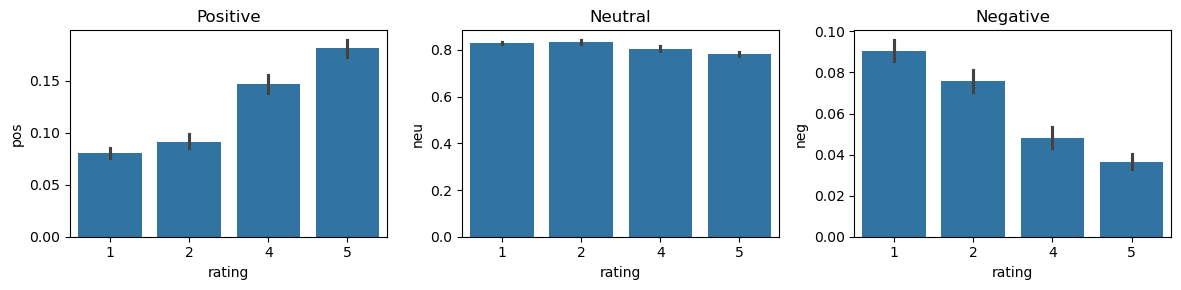

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
sns.barplot(data=vaders, x='rating', y='pos', ax=axs[0])
sns.barplot(data=vaders, x='rating', y='neu', ax=axs[1])
sns.barplot(data=vaders, x='rating', y='neg', ax=axs[2])
axs[0].set_title('Positive')
axs[1].set_title('Neutral')
axs[2].set_title('Negative')
plt.tight_layout()
plt.show()

AFTER PRE-PROCESSING

In [10]:
res = {}
for i, row in df.iterrows():
    text = row['cleaned_review']
    myid = row['unique_id']
    res[myid] = sia.polarity_scores(text)
#pd.DataFrame(res).head

In [12]:
vaders = pd.DataFrame(res).T
vaders = vaders.reset_index().rename(columns={'index': 'unique_id'})
vaders = vaders.merge(df, how='left')
#vaders.head()

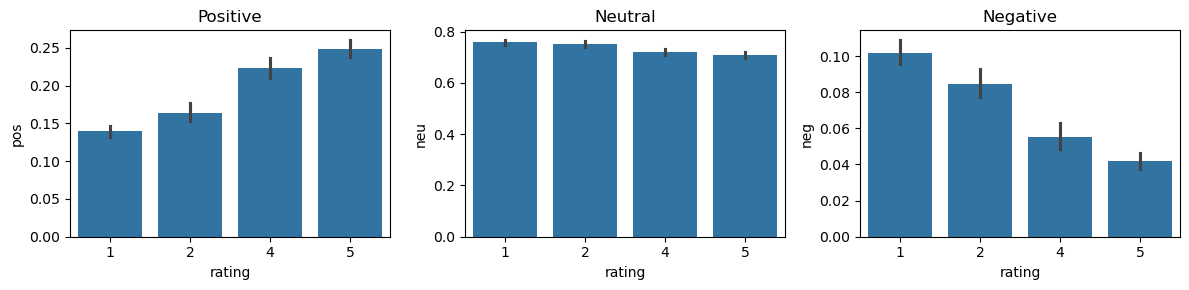

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
sns.barplot(data=vaders, x='rating', y='pos', ax=axs[0])
sns.barplot(data=vaders, x='rating', y='neu', ax=axs[1])
sns.barplot(data=vaders, x='rating', y='neg', ax=axs[2])
axs[0].set_title('Positive')
axs[1].set_title('Neutral')
axs[2].set_title('Negative')
plt.tight_layout()
plt.show()

THAT WAS VADER

Vectorize and Split for review_text/cleaned_review

In [109]:
vectorizer = TfidfVectorizer() # ngram_range=(1,2)
X = vectorizer.fit_transform(df['review_text'])
y = df['Sentiment']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

vectorizer = TfidfVectorizer(max_features=3000)
X = vectorizer.fit_transform(df['cleaned_review'])
y = df['Sentiment']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Feature Selection With/Without

In [113]:
selector = SelectKBest(chi2, k=3000) # Select the 3000 features (words) using the Chi-squared test.
X_train = selector.fit_transform(X_train, y_train)
X_test = selector.transform(X_test)

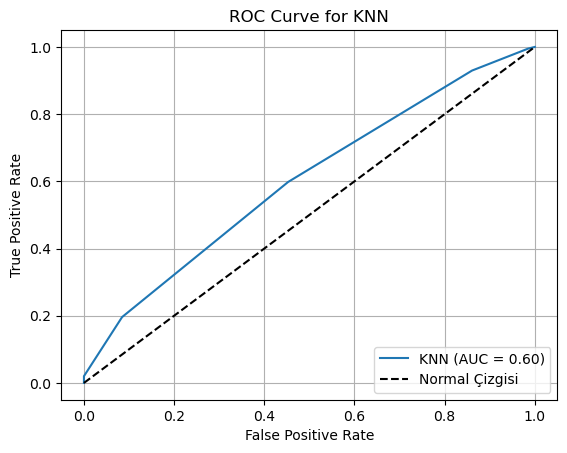

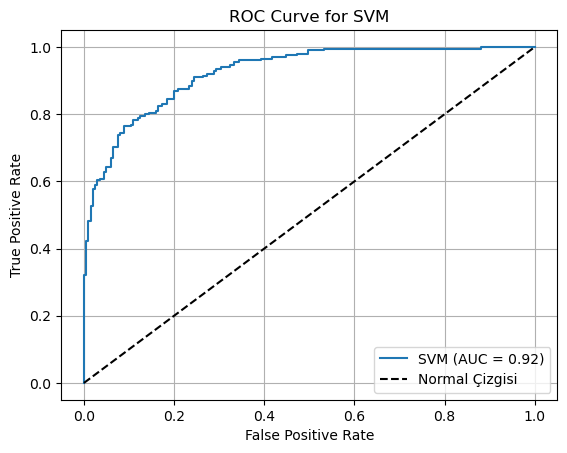

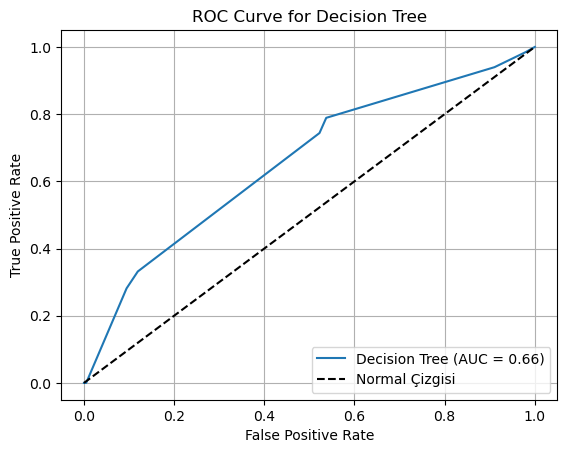

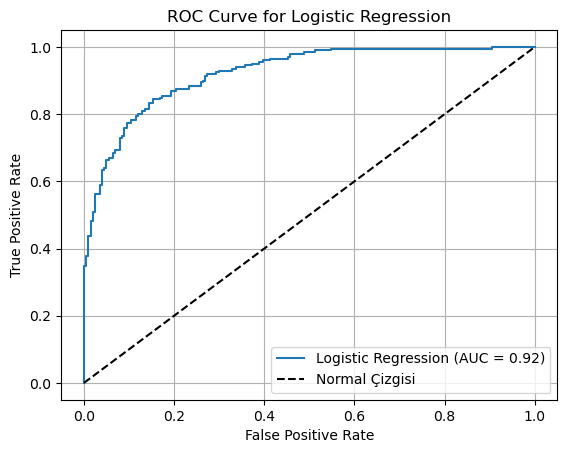

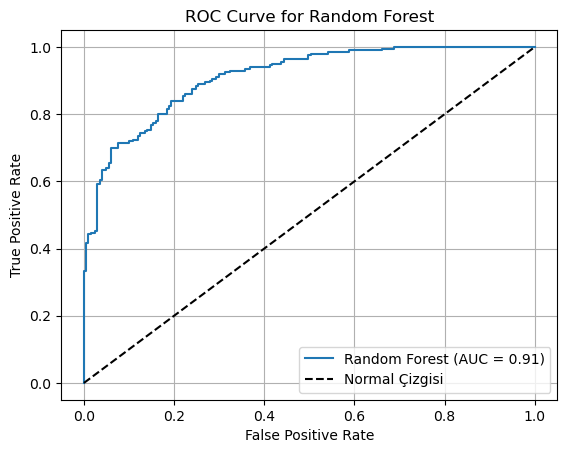

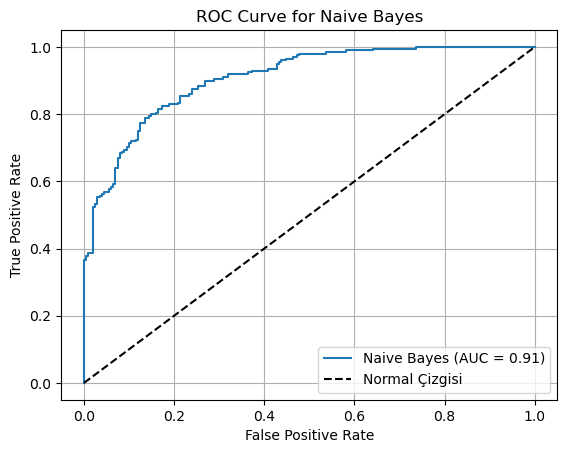

In [115]:
# Models
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', C=1.0, gamma='scale'),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Logistic Regression': LogisticRegression(solver='liblinear', C=1.0),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'Naive Bayes': MultinomialNB()
}

# Saving of CLassifiers and Performance Metrics
results = {}
conf_matrices = {}

for name, model in models.items():
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Getting prediction probabilities for ROC Curve
    if hasattr(model, "predict_proba"):
        y_pred_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_pred_prob = model.decision_function(X_test)
    else:
        continue  # Skip the models that don't support prediction probabilities

    # Calculae ROC Curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob, pos_label=y_test.max())
    roc_auc = auc(fpr, tpr)

    # Plotting ROC Curve
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

    # Normal Line
    plt.plot([0, 1], [0, 1], 'k--', label="Normal Çizgisi")

    # Graphical Specifications
    plt.title(f"ROC Curve for {name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    kappa = cohen_kappa_score(y_test, y_pred)
    score =(acc + prec + rec + f1 + kappa + roc_auc)/6

    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1, 'Kappa': kappa, 'AUC': roc_auc, 'Average Score': score}

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    conf_matrices[name] = cm

                     Accuracy  Precision  Recall  F1-Score     Kappa  \
KNN                    0.5725   0.572838  0.5725  0.572235  0.145214   
SVM                    0.8225   0.822680  0.8225  0.822461  0.644947   
Decision Tree          0.6100   0.619191  0.6100  0.603038  0.221032   
Logistic Regression    0.8400   0.841181  0.8400  0.839832  0.679896   
Random Forest          0.8200   0.820315  0.8200  0.819973  0.640045   
Naive Bayes            0.8250   0.826122  0.8250  0.824816  0.649886   

                          AUC  Average Score  
KNN                  0.601478       0.506127  
SVM                  0.923823       0.809818  
Decision Tree        0.657629       0.553482  
Logistic Regression  0.921873       0.827130  
Random Forest        0.910773       0.805184  
Naive Bayes          0.907498       0.809720  


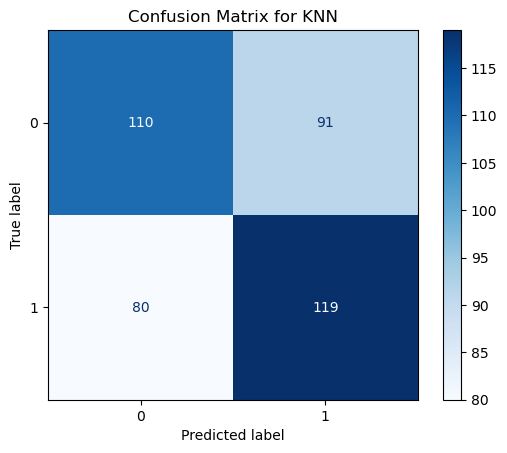

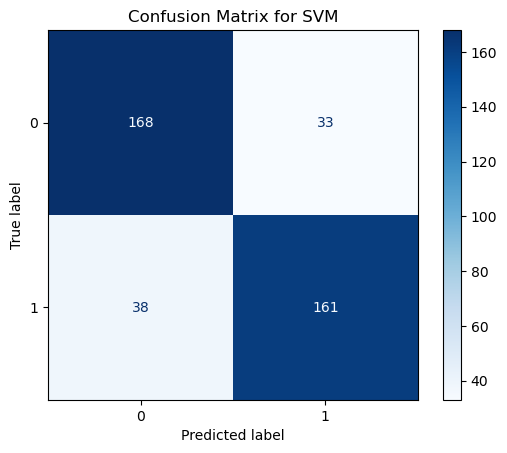

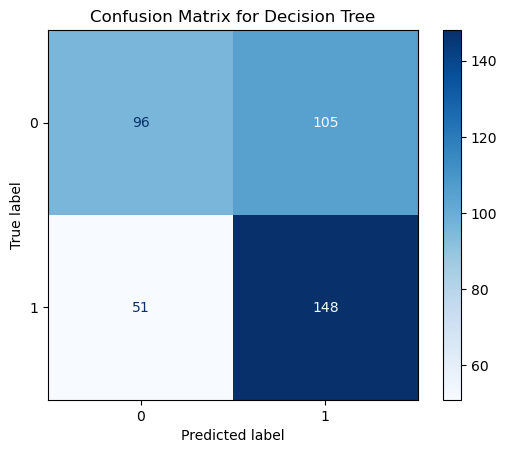

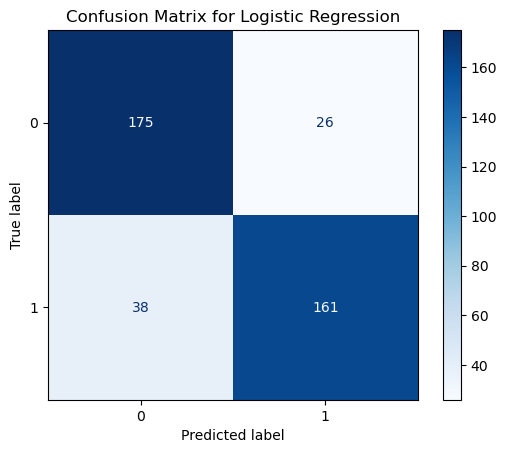

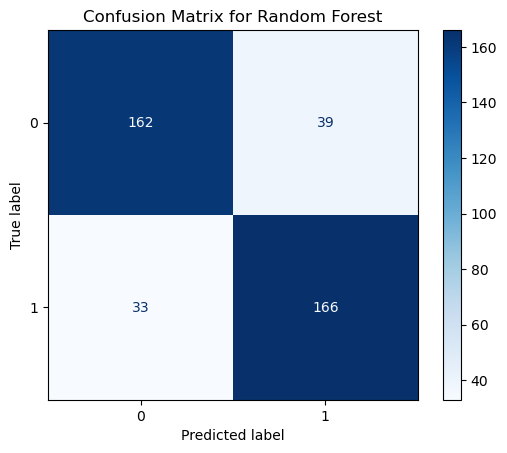

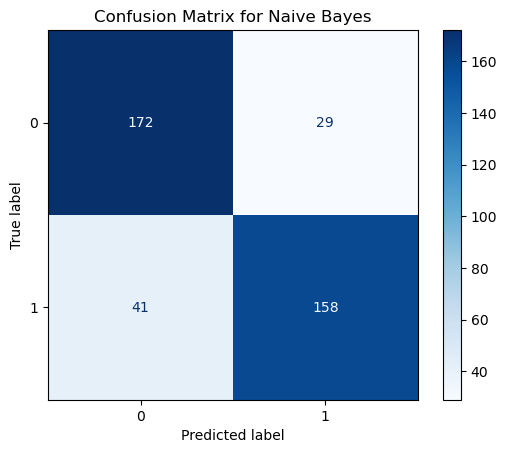

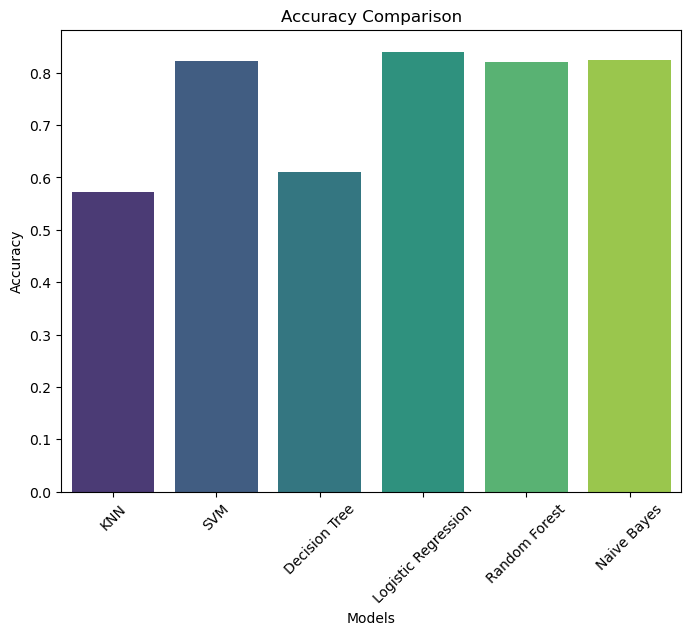

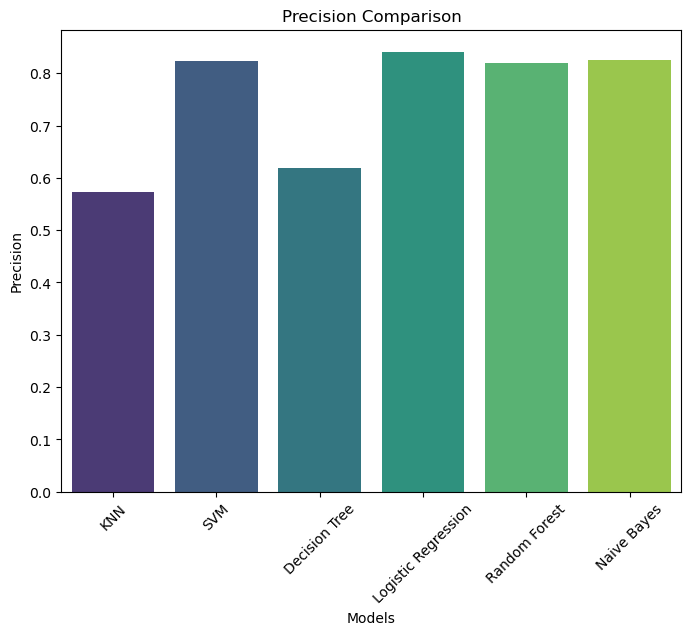

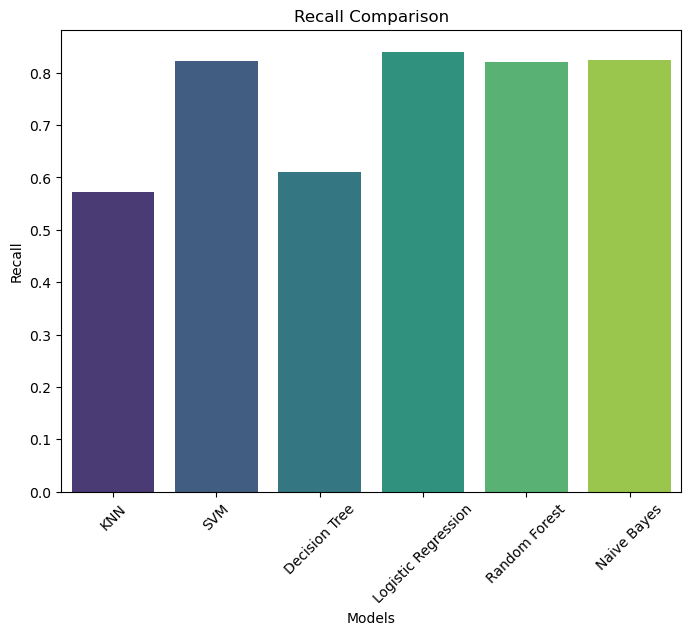

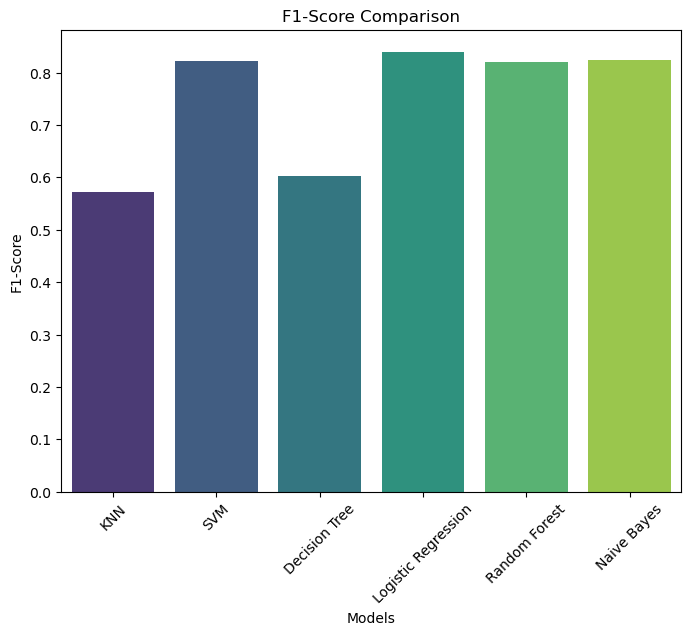

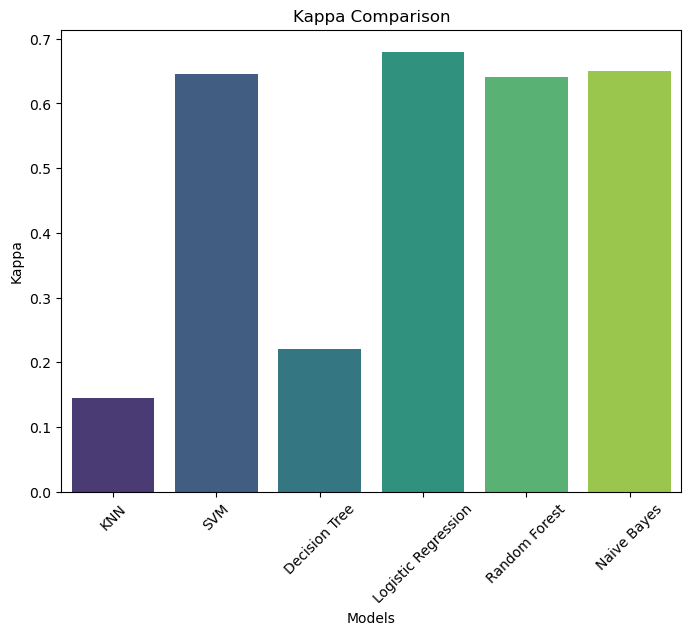

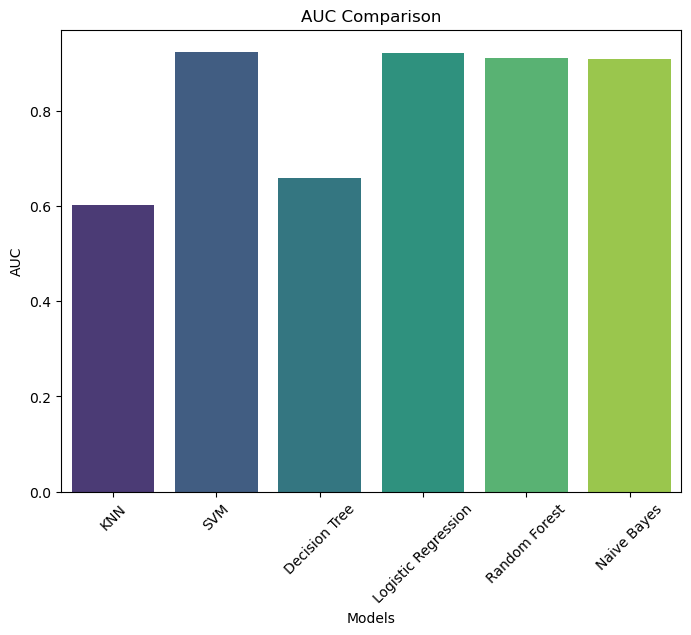

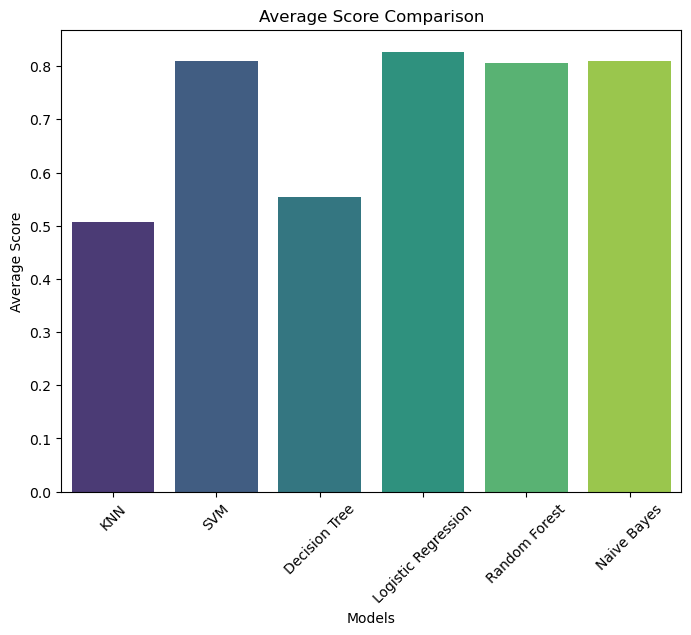

In [117]:
# Show Results
results_df = pd.DataFrame(results).T
print(results_df)

# Plot Confusion Matrix
for name, cm in conf_matrices.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y))
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix for {name}")
    plt.show()

# Show Performance Metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Kappa', 'AUC', 'Average Score']
for metric in metrics:
    plt.figure(figsize=(8, 6))
    sns.barplot(x=results_df.index, y=results_df[metric], palette='viridis', hue=results_df.index, legend=False)
    plt.title(f"{metric} Comparison")
    plt.ylabel(metric)
    plt.xlabel("Models")
    plt.xticks(rotation=45)
    plt.show()

Results for 3000 Features on cleaned_review( one with all the stemming, tokenization, stop_words i.e preprocessing done )

                     Accuracy  Precision  Recall  F1-Score     Kappa  \
KNN                    0.6575   0.657641  0.6575  0.657468  0.315068   
SVM                    0.7900   0.790040  0.7900  0.790000  0.580010   
Decision Tree          0.6450   0.677126  0.6450  0.627354  0.288452   
Logistic Regression    0.8000   0.800020  0.8000  0.799990  0.599970   
Random Forest          0.7950   0.796524  0.7950  0.794785  0.590133   
Naive Bayes            0.7925   0.793047  0.7925  0.792372  0.584896   

                          AUC  Average Score  
KNN                  0.710255       0.609239  
SVM                  0.896647       0.772783  
Decision Tree        0.671854       0.592465  
Logistic Regression  0.901473       0.783575  
Random Forest        0.877797       0.774873  
Naive Bayes          0.879072       0.772398  

Results for 3000 Features on cleaned_review + Feature Selection + Vectorizer does not have max feature attribute which was max_features=3000 before

                     Accuracy  Precision  Recall  F1-Score     Kappa  \
KNN                    0.5400   0.594441  0.5400  0.466051  0.083414   
SVM                    0.8075   0.807716  0.8075  0.807482  0.615038   
Decision Tree          0.6325   0.660904  0.6325  0.614671  0.263416   
Logistic Regression    0.7925   0.792550  0.7925  0.792481  0.584958   
Random Forest          0.8000   0.803782  0.8000  0.799449  0.600210   
Naive Bayes            0.7875   0.787816  0.7875  0.787416  0.574915   

                          AUC  Average Score  
KNN                  0.603003       0.471152  
SVM                  0.891497       0.789456  
Decision Tree        0.656791       0.576797  
Logistic Regression  0.896697       0.775281  
Random Forest        0.890497       0.782323  
Naive Bayes          0.876097       0.766874  

Results for 3000 Features on review_text( one WITHOUT preprocessing done ) ???????

                     Accuracy  Precision  Recall  F1-Score     Kappa  \
KNN                    0.6675   0.667764  0.6675  0.667427  0.335100   
SVM                    0.8625   0.862710  0.8625  0.862470  0.724959   
Decision Tree          0.6175   0.633017  0.6175  0.606806  0.236260   
Logistic Regression    0.8475   0.847567  0.8475  0.847486  0.694969   
Random Forest          0.8325   0.832512  0.8325  0.832501  0.665000   
Naive Bayes            0.8300   0.830785  0.8300  0.829872  0.659906   

                          AUC  Average Score  
KNN                  0.720606       0.620983  
SVM                  0.931423       0.851094  
Decision Tree        0.659704       0.561798  
Logistic Regression  0.927273       0.835383  
Random Forest        0.906223       0.816873  
Naive Bayes          0.909673       0.815039  

Results for 3000 Features on review_text + Feature Selection + Vectorizer does not have max feature attribute which was max_features=3000 before

                     Accuracy  Precision  Recall  F1-Score     Kappa  \
KNN                    0.5725   0.572838  0.5725  0.572235  0.145214   
SVM                    0.8225   0.822680  0.8225  0.822461  0.644947   
Decision Tree          0.6100   0.619191  0.6100  0.603038  0.221032   
Logistic Regression    0.8400   0.841181  0.8400  0.839832  0.679896   
Random Forest          0.8200   0.820315  0.8200  0.819973  0.640045   
Naive Bayes            0.8250   0.826122  0.8250  0.824816  0.649886   

                          AUC  Average Score  
KNN                  0.601478       0.506127  
SVM                  0.923823       0.809818  
Decision Tree        0.657629       0.553482  
Logistic Regression  0.921873       0.827130  
Random Forest        0.910773       0.805184  
Naive Bayes          0.907498       0.809720  

Roberta Pre-Trained Model from HuggingFace

In [25]:
from transformers import pipeline # remnant
from transformers import RobertaForSequenceClassification, AutoModelForSequenceClassification
from transformers import AutoTokenizer, RobertaTokenizer, AutoConfig
from scipy.special import softmax # not needed
import torch # not called but needed for the pre-trained model

In [42]:
MODEL = r"C:\Users\adoma\.cache\huggingface\hub\models--cardiffnlp--twitter-roberta-base-sentiment\snapshots\daefdd1f6ae931839bce4d0f3db0a1a4265cd50f"
model = RobertaForSequenceClassification.from_pretrained(MODEL)
config = AutoConfig.from_pretrained(MODEL)
tokenizer = AutoTokenizer.from_pretrained(MODEL)

# PT

#model.save_pretrained(MODEL) Devil's code

def hf_predict(text):
    encoded_input = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    output = model(**encoded_input)
    scores = output.logits[0].detach().numpy()
    if(scores[0]>scores[2]):
        return 0
    else:
        return 1

df['hf_sentiment'] = df['cleaned_review'].apply(hf_predict)


In [43]:
# Splitting Predicted and True Values
Rob_true = df['Sentiment'].to_numpy()
Rob_pred = df['hf_sentiment'].to_numpy()

In [44]:
namey = "RobertaBPT"
fresults = {}
fconf_matrices = {}

# Metrics
facc = accuracy_score(Rob_true, Rob_pred)
fprec = precision_score(Rob_true, Rob_pred, average='weighted')
frec = recall_score(Rob_true, Rob_pred, average='weighted')
ff1 = f1_score(Rob_true, Rob_pred, average='weighted')
fkappa = cohen_kappa_score(Rob_true, Rob_pred)
fscore =(facc + fprec + frec + ff1 + fkappa)/5

fresults[namey] = {'Accuracy': facc, 'Precision': fprec, 'Recall': frec, 'F1-Score': ff1, 'Kappa': fkappa, 'Average Score': fscore}

# Confusion Matrix
cm1 = confusion_matrix(Rob_true, Rob_pred)
fconf_matrices[namey] = cm1

2000 rows on review_text:

               RobertaBPT
Accuracy         0.890000
Precision        0.892387
Recall           0.890000
F1-Score         0.889832
Kappa            0.780000
Average Score    0.868444


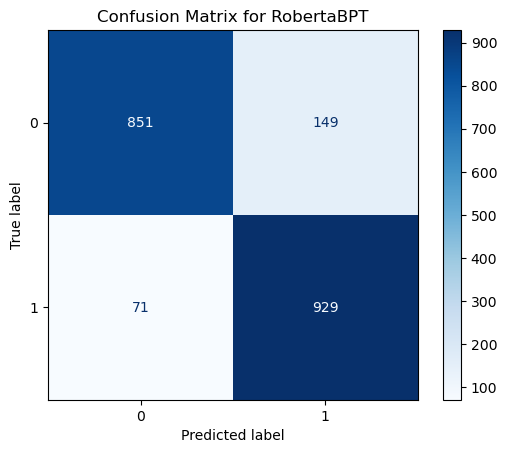

In [30]:
# Show Results
Robresults_df = pd.DataFrame(fresults)
print(Robresults_df)

# Roberta Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=np.unique(y))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for RobertaBPT")
plt.show()


2000 rows on cleaned_review:

               RobertaBPT
Accuracy         0.716500
Precision        0.727830
Recall           0.716500
F1-Score         0.712931
Kappa            0.433000
Average Score    0.661352


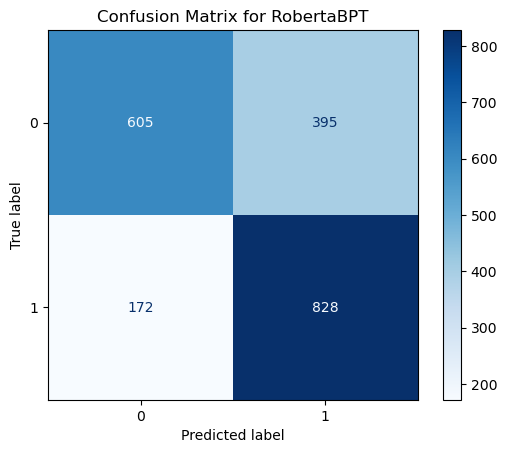

In [45]:
# Show Results
Robresults_df = pd.DataFrame(fresults)
print(Robresults_df)

# Roberta Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=np.unique(y))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for RobertaBPT")
plt.show()

Performed so bad, i had to check again ---> 2000 rows on review_text again: Confirmed --> my pre-processing is trash

               RobertaBPT
Accuracy         0.890000
Precision        0.892387
Recall           0.890000
F1-Score         0.889832
Kappa            0.780000
Average Score    0.868444


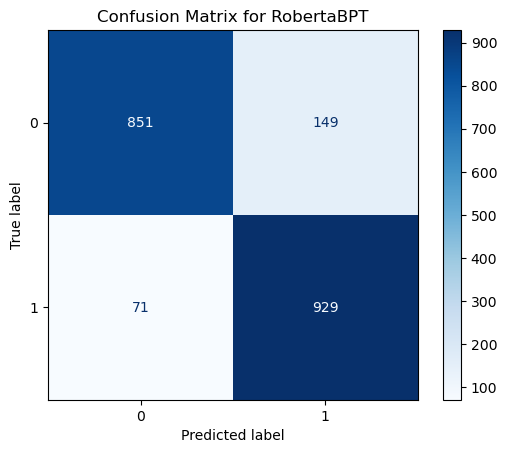

In [34]:
# Show Results
Robresults_df = pd.DataFrame(fresults)
print(Robresults_df)

# Roberta Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=np.unique(y))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for RobertaBPT")
plt.show()